<a href="https://colab.research.google.com/github/swetak0911/data-mining-assignment-2/blob/main/Medallion_Book_Recommender.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Mining Lab Assignment: Book Recommender on a Medallion Data Lake
**Dataset:** Book-Crossing (Users, Books, Book-Ratings)  
LIT2023019 - Sweta Kumari

## Step 1: Set up the data lake and build the Bronze layer

In [ ]:
import os, glob, zipfile, subprocess, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

# Data lake folders
for d in ['bronze', 'silver', 'gold']:
    os.makedirs(d, exist_ok=True)
print('Folders:', [d for d in ['bronze', 'silver', 'gold'] if os.path.isdir(d)])

Folders: ['bronze', 'silver', 'gold']


In [ ]:
URL = 'https://cdn.freecodecamp.org/project-data/books/book-crossings.zip'

if not glob.glob('**/BX-Users.csv', recursive=True):
    subprocess.run(['wget', '-q', '-O', 'book-crossings.zip', URL], check=True)
    with zipfile.ZipFile('book-crossings.zip') as z:
        z.extractall('raw')

def find(name):
    return glob.glob(f'**/{name}', recursive=True)[0]

USERS_PATH   = find('BX-Users.csv')
BOOKS_PATH   = find('BX-Books.csv')
RATINGS_PATH = find('BX-Book-Ratings.csv')
print(USERS_PATH, BOOKS_PATH, RATINGS_PATH, sep='\n')

raw/BX-Users.csv
raw/BX-Books.csv
raw/BX-Book-Ratings.csv


In [ ]:

read_kw = dict(sep=';', encoding='latin-1', dtype=str, escapechar='\\', on_bad_lines='skip')

users_raw   = pd.read_csv(USERS_PATH, **read_kw)
books_raw   = pd.read_csv(BOOKS_PATH, **read_kw)
ratings_raw = pd.read_csv(RATINGS_PATH, **read_kw)

# Only addition allowed in Bronze: ingestion timestamp
ts = pd.Timestamp.now()
for df in (users_raw, books_raw, ratings_raw):
    df['ingestion_timestamp'] = ts

users_raw.to_parquet('bronze/users.parquet', index=False)
books_raw.to_parquet('bronze/books.parquet', index=False)
ratings_raw.to_parquet('bronze/ratings.parquet', index=False)
print(os.listdir('bronze'))

['books.parquet', 'users.parquet', 'ratings.parquet']


## Step 2: Explore the Bronze data (EDA)

In [ ]:
users   = pd.read_parquet('bronze/users.parquet')
books   = pd.read_parquet('bronze/books.parquet')
ratings = pd.read_parquet('bronze/ratings.parquet')

for name, df in [('users', users), ('books', books), ('ratings', ratings)]:
    print(f'===== {name}: shape = {df.shape} =====')
    print(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum()}))
    print()

===== users: shape = (278858, 4) =====
                              dtype  missing
User-ID                      object        0
Location                     object        0
Age                          object   110762
ingestion_timestamp  datetime64[us]        0

===== books: shape = (271379, 9) =====
                              dtype  missing
ISBN                         object        0
Book-Title                   object        0
Book-Author                  object        2
Year-Of-Publication          object        0
Publisher                    object        2
Image-URL-S                  object        0
Image-URL-M                  object        0
Image-URL-L                  object        0
ingestion_timestamp  datetime64[us]        0

===== ratings: shape = (1149780, 4) =====
                              dtype  missing
User-ID                      object        0
ISBN                         object        0
Book-Rating                  object        0
ingestion_timestamp  da

**Finding (shape / dtypes / missing):** Users ≈ 278k rows, Books ≈ 271k rows, Ratings ≈ 1.1M rows. Bronze stores every column as text (`object`) on purpose, so the raw values are preserved. `Age` has a large share of missing values (~40%) and `Book-Author`/`Publisher` have a handful of nulls.  
**Silver action:** convert `Age`, `Year-Of-Publication` and `Book-Rating` to numeric (invalid → null), fill missing ages with the median, and handle the few null text values.

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Ratings equal to 0: 716,109 of 1,149,780 (62.3%)


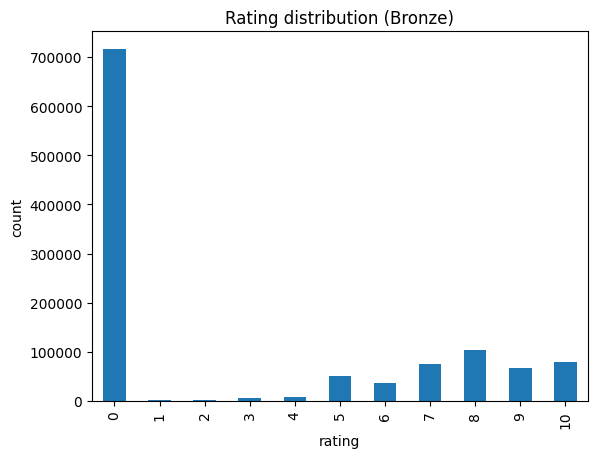

In [ ]:
r = ratings.copy()
r['Book-Rating'] = pd.to_numeric(r['Book-Rating'], errors='coerce')
print(r['Book-Rating'].value_counts().sort_index())
print(f"\nRatings equal to 0: {(r['Book-Rating']==0).sum():,} of {len(r):,} ({(r['Book-Rating']==0).mean():.1%})")

r['Book-Rating'].value_counts().sort_index().plot(kind='bar', title='Rating distribution (Bronze)')
plt.xlabel('rating'); plt.ylabel('count'); plt.show()

**Finding (ratings):** About 60%+ of all rows are `0`, which means "no explicit rating" (implicit interaction), not a bad rating. Explicit ratings 1–10 are skewed towards 7–10.  
**Silver action:** drop all rating = 0 rows and keep only 1–10.

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64
Age < 5   : 882
Age > 100 : 366
Age missing: 110762 (39.7%)


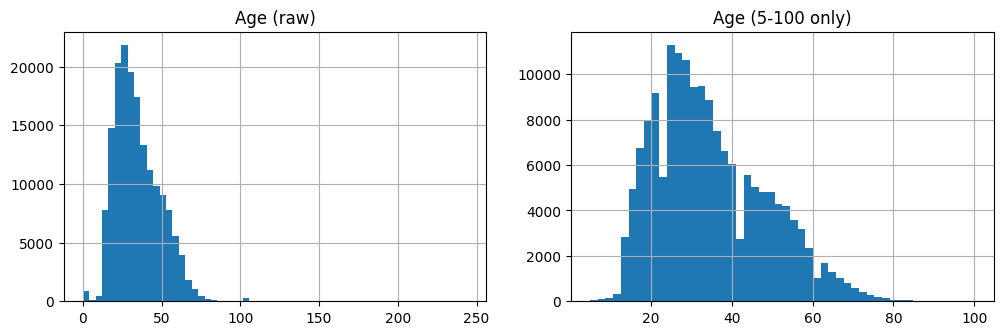

In [ ]:
age = pd.to_numeric(users['Age'], errors='coerce')
print(age.describe())
print('Age < 5   :', (age < 5).sum())
print('Age > 100 :', (age > 100).sum())
print('Age missing:', age.isna().sum(), f'({age.isna().mean():.1%})')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
age.dropna().hist(bins=60, ax=ax[0]); ax[0].set_title('Age (raw)')
age[(age >= 5) & (age <= 100)].hist(bins=50, ax=ax[1]); ax[1].set_title('Age (5-100 only)')
plt.show()

**Finding (age):** Ages include impossible values (0, 1, and values up to 200+), and ~40% are missing. The valid range is concentrated around 20–40.  
**Silver action:** set age < 5 or > 100 to null, then fill all nulls with the median of the valid ages.

count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64
Year == 0        : 4619
Year > 2026 (future): 11
Non-numeric year : 0


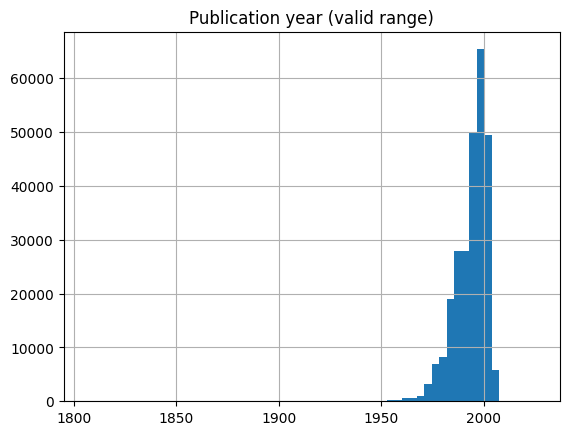

In [ ]:
year = pd.to_numeric(books['Year-Of-Publication'], errors='coerce')
cur_year = pd.Timestamp.now().year
print(year.describe())
print('Year == 0        :', (year == 0).sum())
print(f'Year > {cur_year} (future):', (year > cur_year).sum())
print('Non-numeric year :', year.isna().sum())

year[(year > 1800) & (year <= cur_year)].hist(bins=60)
plt.title('Publication year (valid range)'); plt.show()

**Finding (publication year):** Many books have year `0` and some have future years (e.g. 2030, 2050), plus a few non-numeric values caused by shifted columns in the raw file.  
**Silver action:** convert to numeric, set 0 / future years / non-numeric to null (not filled, since a wrong year is better left unknown).

Ratings per user:
 count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64 

Ratings per book:
 count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64 

Users with >=  1 ratings: 105,283   |   Books with >=  1 ratings: 340,556
Users with >=  2 ratings:  46,117   |   Books with >=  2 ratings: 143,511
Users with >=  5 ratings:  22,816   |   Books with >=  5 ratings:  43,765
Users with >= 10 ratings:  13,097   |   Books with >= 10 ratings:  18,319
Users with >= 20 ratings:   7,369   |   Books with >= 20 ratings:   7,490
Users with >= 50 ratings:   3,427   |   Books with >= 50 ratings:   2,185


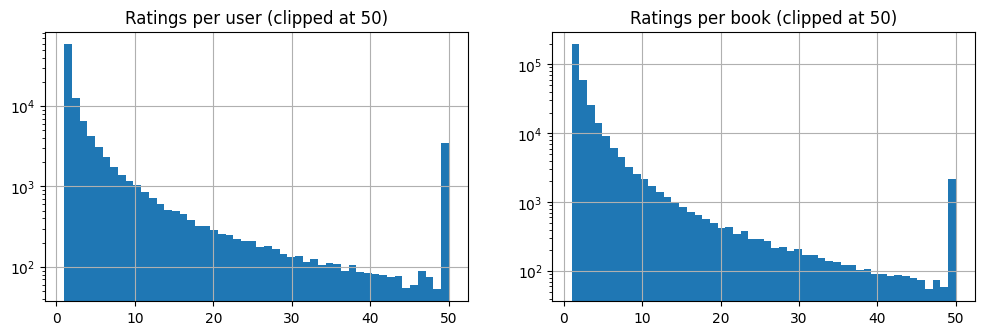


Explicit only -> users with >=10: 7334 | books with >=10: 5645
Explicit only -> median ratings per user: 1.0 | per book: 1.0


In [ ]:
r0 = r.copy()
per_user = r0.groupby('User-ID').size()
per_book = r0.groupby('ISBN').size()
print('Ratings per user:\n', per_user.describe(), '\n')
print('Ratings per book:\n', per_book.describe(), '\n')

for k in [1, 2, 5, 10, 20, 50]:
    print(f'Users with >= {k:>2} ratings: {(per_user>=k).sum():>7,}   |   Books with >= {k:>2} ratings: {(per_book>=k).sum():>7,}')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
per_user.clip(upper=50).hist(bins=50, ax=ax[0], log=True); ax[0].set_title('Ratings per user (clipped at 50)')
per_book.clip(upper=50).hist(bins=50, ax=ax[1], log=True); ax[1].set_title('Ratings per book (clipped at 50)')
plt.show()

# Same stats on EXPLICIT ratings only (this is what the model will actually use)
expl = r0[r0['Book-Rating'] > 0]
pu, pb = expl.groupby('User-ID').size(), expl.groupby('ISBN').size()
print('\nExplicit only -> users with >=10:', (pu>=10).sum(), '| books with >=10:', (pb>=10).sum())
print('Explicit only -> median ratings per user:', pu.median(), '| per book:', pb.median())

**Finding (ratings per user / book):** Extremely long-tailed: the median user and the median book have only 1–2 ratings, while a few users/books have thousands. Most users/books are far too sparse for similarity to be reliable.  
**Silver action:** after cleaning, keep only users and books with at least a minimum number of ratings (threshold chosen in Step 3 from this table).

In [ ]:
n_users_r, n_books_r = r['User-ID'].nunique(), r['ISBN'].nunique()
sparsity_all  = 1 - len(r) / (n_users_r * n_books_r)
expl = r[r['Book-Rating'] > 0]
sparsity_expl = 1 - len(expl) / (expl['User-ID'].nunique() * expl['ISBN'].nunique())
print(f'All ratings      : {len(r):,} / ({n_users_r:,} x {n_books_r:,}) -> sparsity {sparsity_all:.4%}')
print(f'Explicit (1-10)  : {len(expl):,} / ({expl["User-ID"].nunique():,} x {expl["ISBN"].nunique():,}) -> sparsity {sparsity_expl:.4%}')

All ratings      : 1,149,780 / (105,283 x 340,556) -> sparsity 99.9968%
Explicit (1-10)  : 433,671 / (77,805 x 185,973) -> sparsity 99.9970%


**Finding (sparsity):** The user-book matrix is ~99.99% empty, so a dense matrix is impossible (it would need hundreds of GB).  
**Silver / Gold action:** filter to active users and popular books to densify the data, and store the matrix as a **sparse CSR matrix** in Gold.

## Step 3: Clean the data and build the Silver layer

In [ ]:
users   = pd.read_parquet('bronze/users.parquet')
books   = pd.read_parquet('bronze/books.parquet')
ratings = pd.read_parquet('bronze/ratings.parquet')

# Standard column names + drop the Bronze-only ingestion column (re-stamped at the end)
users   = users.rename(columns={'User-ID': 'user_id', 'Location': 'location', 'Age': 'age'}).drop(columns='ingestion_timestamp')
books   = books.rename(columns={'ISBN': 'isbn', 'Book-Title': 'title', 'Book-Author': 'author',
                                'Year-Of-Publication': 'year', 'Publisher': 'publisher'}).drop(columns='ingestion_timestamp')
ratings = ratings.rename(columns={'User-ID': 'user_id', 'ISBN': 'isbn', 'Book-Rating': 'rating'}).drop(columns='ingestion_timestamp')

# 1) Drop the image-URL columns (not needed)
books = books.drop(columns=[c for c in books.columns if c.startswith('Image-URL')])

# 2) Remove duplicate rows
print('Before dedup  :', len(users), len(books), len(ratings))
users   = users.drop_duplicates().drop_duplicates('user_id')
books   = books.drop_duplicates().drop_duplicates('isbn')
ratings = ratings.drop_duplicates().drop_duplicates(['user_id', 'isbn'], keep='last')
print('After dedup   :', len(users), len(books), len(ratings))

Before dedup  : 278858 271379 1149780
After dedup   : 278858 271379 1149780


In [ ]:
# 3) Ratings: numeric, remove 0 (no explicit rating), keep 1-10
ratings['rating'] = pd.to_numeric(ratings['rating'], errors='coerce')
ratings = ratings[ratings['rating'].between(1, 10)].copy()
ratings['rating'] = ratings['rating'].astype(int)
print('Explicit ratings kept:', len(ratings))

# 4) Ages: <5 or >100 -> null, then fill with median
users['age'] = pd.to_numeric(users['age'], errors='coerce')
users.loc[(users['age'] < 5) | (users['age'] > 100), 'age'] = np.nan
median_age = users['age'].median()
users['age'] = users['age'].fillna(median_age).astype(int)
print('Median age used for filling:', median_age)

# 5) Split Location -> city, state, country
loc = users['location'].fillna('').str.split(',', expand=True)
users['city']    = loc[0]
users['state']   = loc[1] if loc.shape[1] > 1 else np.nan
users['country'] = loc[loc.shape[1] - 1] if loc.shape[1] > 2 else (loc[1] if loc.shape[1] == 2 else np.nan)
users = users.drop(columns='location')

# 6) Publication year: 0 / future / non-numeric -> null
cur_year = pd.Timestamp.now().year
books['year'] = pd.to_numeric(books['year'], errors='coerce')
books.loc[(books['year'] == 0) | (books['year'] > cur_year), 'year'] = np.nan
books['year'] = books['year'].astype('Int64')

Explicit ratings kept: 433671
Median age used for filling: 32.0


In [ ]:
# 7) Text cleaning: strip, collapse spaces, standardise case
def clean_text(s, case='title'):
    s = s.astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
    s = s.str.title() if case == 'title' else s.str.lower()
    return s.replace('', pd.NA)

for c in ['title', 'author', 'publisher']:
    books[c] = clean_text(books[c], 'title')
for c in ['city', 'state', 'country']:
    users[c] = clean_text(users[c], 'lower')
books['isbn'] = books['isbn'].str.strip().str.upper()
ratings['isbn'] = ratings['isbn'].str.strip().str.upper()
books = books.dropna(subset=['title']).drop_duplicates('isbn')

# Users with a missing country etc. keep their rows (nulls are fine for these columns)
users['user_id']   = users['user_id'].astype(int)
ratings['user_id'] = ratings['user_id'].astype(int)

# 8) Referential integrity: ratings must point to an existing user AND book
before = len(ratings)
ratings = ratings[ratings['user_id'].isin(users['user_id']) & ratings['isbn'].isin(books['isbn'])]
print(f'Ratings after integrity check: {len(ratings):,} (removed {before-len(ratings):,})')

Ratings after integrity check: 383,853 (removed 49,818)


In [ ]:
# 9) Minimum-ratings threshold: look at the trade-off first (justification from the EDA)
rows = []
for k in [1, 5, 10, 15, 20, 30, 50]:
    rr = ratings
    while True:
        uc, bc = rr['user_id'].value_counts(), rr['isbn'].value_counts()
        r2 = rr[rr['user_id'].isin(uc[uc >= k].index) & rr['isbn'].isin(bc[bc >= k].index)]
        if len(r2) == len(rr): break
        rr = r2
    nu, nb = rr['user_id'].nunique(), rr['isbn'].nunique()
    rows.append({'threshold': k, 'users': nu, 'books': nb, 'ratings': len(rr),
                 'ratings_kept_%': round(100*len(rr)/len(ratings), 1),
                 'density_%': round(100*len(rr)/max(nu*nb, 1), 4)})
print(pd.DataFrame(rows).to_string(index=False))

 threshold  users  books  ratings  ratings_kept_%  density_%
         1  68092 149723   383853           100.0     0.0038
         5   6858   9092   115332            30.0     0.1850
        10   1820   2030    41469            10.8     1.1224
        15      0      0        0             0.0     0.0000
        20      0      0        0             0.0     0.0000
        30      0      0        0             0.0     0.0000
        50      0      0        0             0.0     0.0000


### Chosen threshold: **users ≥ 10 ratings and books ≥ 10 ratings**
**Justification (from the EDA):** the median user/book has only 1–2 ratings, so cosine similarity on such vectors is just noise (two books rated by the same single user look "100% similar"). A threshold of 10 gives every book at least 10 raters, which is enough overlap for a stable similarity, and every user at least 10 rated books, so there is enough taste information to recommend from. As the table shows, 10 keeps a healthy share of the explicit ratings while the matrix becomes much denser than the raw ~99.99% empty one. Higher thresholds (30, 50) throw away too many users/books (hurting coverage), while lower ones (1, 5) keep the noisy long tail.  
Because removing users can push some books below the threshold (and vice versa), the filter is applied **repeatedly until stable**.

In [ ]:
MIN_USER_RATINGS = 10
MIN_BOOK_RATINGS = 10

while True:
    uc, bc = ratings['user_id'].value_counts(), ratings['isbn'].value_counts()
    keep = ratings['user_id'].isin(uc[uc >= MIN_USER_RATINGS].index) & ratings['isbn'].isin(bc[bc >= MIN_BOOK_RATINGS].index)
    if keep.all(): break
    ratings = ratings[keep]

users = users[users['user_id'].isin(ratings['user_id'])].reset_index(drop=True)
books = books[books['isbn'].isin(ratings['isbn'])].reset_index(drop=True)
ratings = ratings.reset_index(drop=True)

ts = pd.Timestamp.now()
for df in (users, books, ratings):
    df['processed_timestamp'] = ts

users.to_parquet('silver/users.parquet', index=False)
books.to_parquet('silver/books.parquet', index=False)
ratings.to_parquet('silver/ratings.parquet', index=False)
print('Silver ->', 'users', users.shape, '| books', books.shape, '| ratings', ratings.shape)
print('Silver sparsity: %.4f%%' % (100 * (1 - len(ratings) / (len(users) * len(books)))))
users.head()

Silver -> users (1820, 6) | books (2030, 6) | ratings (41469, 4)
Silver sparsity: 98.8776%


,user_id,age,city,state,country,processed_timestamp
0,243,32,arden hills,minnesota,<NA>,2026-11-25 17:47:30.878550
1,254,24,minneapolis,minnesota,<NA>,2026-11-25 17:47:30.878550
2,638,20,san diego,california,<NA>,2026-11-25 17:47:30.878550
3,805,34,sonoma,california,<NA>,2026-11-25 17:47:30.878550
4,882,23,berkeley,california,<NA>,2026-11-25 17:47:30.878550


## Step 4: Build the Gold layer

In [ ]:
users   = pd.read_parquet('silver/users.parquet')
books   = pd.read_parquet('silver/books.parquet')
ratings = pd.read_parquet('silver/ratings.parquet')

# Stable integer indices for the matrix
user_ids = np.sort(ratings['user_id'].unique())
isbns    = np.sort(ratings['isbn'].unique())
user_index = pd.Series(np.arange(len(user_ids)), index=user_ids)
book_index = pd.Series(np.arange(len(isbns)),    index=isbns)

rows = ratings['user_id'].map(user_index).to_numpy()
cols = ratings['isbn'].map(book_index).to_numpy()

# A) Sparse user-book rating matrix (rows = users, cols = books)
user_book = sparse.csr_matrix((ratings['rating'].to_numpy(dtype=float), (rows, cols)),
                              shape=(len(user_ids), len(isbns)))
sparse.save_npz('gold/user_book_matrix.npz', user_book)
pd.DataFrame({'user_id': user_ids, 'user_idx': np.arange(len(user_ids))}).to_parquet('gold/user_index.parquet', index=False)
pd.DataFrame({'isbn': isbns, 'book_idx': np.arange(len(isbns))}).to_parquet('gold/book_index.parquet', index=False)

# B) Book lookup table (id, title, author)
book_lookup = books[['isbn', 'title', 'author']].rename(columns={'isbn': 'book_id'})
book_lookup['book_idx'] = book_lookup['book_id'].map(book_index)
book_lookup.to_parquet('gold/book_lookup.parquet', index=False)

# C) User-level and book-level aggregates
user_stats = ratings.groupby('user_id')['rating'].agg(avg_rating='mean', n_ratings='count').reset_index()
book_stats = ratings.groupby('isbn')['rating'].agg(avg_rating='mean', n_ratings='count').reset_index().rename(columns={'isbn': 'book_id'})
user_stats.to_parquet('gold/user_stats.parquet', index=False)
book_stats.to_parquet('gold/book_stats.parquet', index=False)

print('Matrix shape (users x books):', user_book.shape, '| stored non-zeros:', user_book.nnz)
print('Matrix sparsity: %.4f%%' % (100 * (1 - user_book.nnz / (user_book.shape[0] * user_book.shape[1]))))
print('Memory (sparse): %.1f MB  vs dense would be %.1f GB' % (
    (user_book.data.nbytes + user_book.indices.nbytes + user_book.indptr.nbytes) / 1e6,
    user_book.shape[0] * user_book.shape[1] * 8 / 1e9))
print(os.listdir('gold'))
book_stats.sort_values('n_ratings', ascending=False).merge(book_lookup, on='book_id').head(5)

Matrix shape (users x books): (1820, 2030) | stored non-zeros: 41469
Matrix sparsity: 98.8776%
Memory (sparse): 0.5 MB  vs dense would be 0.0 GB
['book_index.parquet', 'user_book_matrix.npz', 'user_index.parquet', 'book_stats.parquet', 'user_stats.parquet', 'book_lookup.parquet']


,book_id,avg_rating,n_ratings,title,author,book_idx
0,0316666343,8.237668,223,The Lovely Bones: A Novel,Alice Sebold,281
1,0385504209,8.610169,177,The Da Vinci Code,Dan Brown,662
2,0312195516,8.492424,132,The Red Tent (Bestselling Backlist),Anita Diamant,205
3,0142001740,8.664000,125,The Secret Life Of Bees,Sue Monk Kidd,176
4,059035342X,9.042017,119,Harry Potter And The Sorcerer'S Stone (Harry P...,J. K. Rowling,1520


## Step 5: Item-based collaborative filtering recommender

In [ ]:
from sklearn.neighbors import NearestNeighbors

# 1) Load from Gold; rows = books, columns = users
user_book   = sparse.load_npz('gold/user_book_matrix.npz')
user_index  = pd.read_parquet('gold/user_index.parquet')
book_lookup = pd.read_parquet('gold/book_lookup.parquet').sort_values('book_idx').reset_index(drop=True)
book_stats  = pd.read_parquet('gold/book_stats.parquet')

book_user = user_book.T.tocsr()                      # (n_books x n_users)
print('Book x User matrix:', book_user.shape)

# 2) Cosine similarity between books via NearestNeighbors (brute force works with sparse input)
knn = NearestNeighbors(metric='cosine', algorithm='brute', n_jobs=-1)
knn.fit(book_user)

titles      = book_lookup['title'].tolist()
title_of    = dict(zip(book_lookup['book_idx'], book_lookup['title']))
author_of   = dict(zip(book_lookup['book_idx'], book_lookup['author']))
n_rat_of    = dict(zip(book_lookup['book_id'].map(dict(zip(book_lookup['book_id'], book_lookup['book_idx']))),
                       book_lookup['book_id'].map(book_stats.set_index('book_id')['n_ratings'])))
isbn_to_idx = dict(zip(book_lookup['book_id'], book_lookup['book_idx']))

Book x User matrix: (2030, 1820)


In [ ]:
_nn_cache = {}
def neighbours(book_idx, k=50):
    """Top-k most similar books (idx, similarity), excluding the book itself and other editions of the same title."""
    if book_idx not in _nn_cache:
        dist, ind = knn.kneighbors(book_user[book_idx], n_neighbors=min(k + 1, book_user.shape[0]))
        out, seen = [], {title_of[book_idx]}
        for d, i in zip(dist[0], ind[0]):
            if i == book_idx or title_of[i] in seen:      # skip self & duplicate editions
                continue
            seen.add(title_of[i])
            out.append((i, 1 - d))                          # cosine similarity = 1 - cosine distance
        _nn_cache[book_idx] = out
    return _nn_cache[book_idx]

def find_book(title):
    """Case-insensitive match; if several books match, take the one with most ratings."""
    m = book_lookup[book_lookup['title'].str.lower() == title.strip().lower()]
    if m.empty:
        m = book_lookup[book_lookup['title'].str.lower().str.contains(re.escape(title.strip().lower()), na=False)]
    if m.empty:
        return None
    return int(m.merge(book_stats, on='book_id').sort_values('n_ratings', ascending=False).iloc[0]['book_idx'])

# 3) Most similar books for a given title
def similar_books(title, n=10):
    idx = find_book(title)
    if idx is None:
        print(f'"{title}" not found in the Gold book table.'); return None
    res = neighbours(idx, k=max(50, n * 3))[:n]
    print(f'Books similar to: {title_of[idx]}  ({author_of[idx]})')
    return pd.DataFrame({'title': [title_of[i] for i, _ in res],
                         'author': [author_of[i] for i, _ in res],
                         'similarity': [round(s, 3) for _, s in res]})

# Pick a popular book automatically so the demo always works
popular_title = book_stats.sort_values('n_ratings', ascending=False).merge(book_lookup, on='book_id').iloc[0]['title']
similar_books(popular_title)

Books similar to: The Lovely Bones: A Novel  (Alice Sebold)


,title,author,similarity
0,Where The Heart Is (Oprah'S Book Club (Paperba...,Billie Letts,0.219
1,Lucky : A Memoir,Alice Sebold,0.218
2,The Da Vinci Code,Dan Brown,0.178
3,The Pilot'S Wife : A Novel,Anita Shreve,0.176
4,Good In Bed,Jennifer Weiner,0.176
5,Nights In Rodanthe,Nicholas Sparks,0.170
6,The Pact: A Love Story,Jodi Picoult,0.168
7,The Lake House,James Patterson,0.166
8,Lucky,Alice Sebold,0.165
9,White Oleander : A Novel (Oprah'S Book Club),Janet Fitch,0.154


In [ ]:
# 4) recommend(user_id, n)
def recommend(user_id, n=10, like_threshold=8, k=50):
    if user_id not in set(user_index['user_id']):
        print(f'User {user_id} is not in the Gold matrix (filtered out in Silver).'); return None
    u = int(user_index.loc[user_index['user_id'] == user_id, 'user_idx'].iloc[0])
    row = user_book[u]
    read_idx, read_rating = row.indices, row.data

    liked = [(i, r) for i, r in zip(read_idx, read_rating) if r >= like_threshold]
    if not liked:                                    # fallback: user's top-5 rated books
        order = np.argsort(-read_rating)[:5]
        liked = [(read_idx[o], read_rating[o]) for o in order]

    read_titles = {title_of[i] for i in read_idx}    # also hides other editions of already-read books
    scores = {}
    for i, r in liked:
        for j, sim in neighbours(i, k):
            if title_of[j] in read_titles:           # remove books the user has already read
                continue
            scores[j] = scores.get(j, 0.0) + sim * r # similarity weighted by the user's rating
    top = sorted(scores.items(), key=lambda x: -x[1])[:n]
    return pd.DataFrame({'rank': range(1, len(top) + 1),
                         'title': [title_of[j] for j, _ in top],
                         'author': [author_of[j] for j, _ in top],
                         'score': [round(s, 2) for _, s in top]})

## Step 6: Demo and sanity check

In [ ]:
def liked_books(user_id, like_threshold=8, top=10):
    u = int(user_index.loc[user_index['user_id'] == user_id, 'user_idx'].iloc[0])
    row = user_book[u]
    df = pd.DataFrame({'title': [title_of[i] for i in row.indices],
                       'author': [author_of[i] for i in row.indices],
                       'rating': row.data.astype(int)})
    return df[df['rating'] >= like_threshold].sort_values('rating', ascending=False).head(top).reset_index(drop=True)

# 3 different users: random active users (fixed seed for reproducibility)
rng = np.random.default_rng(42)
user_stats = pd.read_parquet('gold/user_stats.parquet')
demo_users = rng.choice(user_stats.loc[user_stats['n_ratings'] >= 20, 'user_id'].to_numpy(), size=3, replace=False)

pd.set_option('display.max_colwidth', 70)
for uid in demo_users:
    print('=' * 100)
    print(f'USER {uid}  (rated {int(user_stats.loc[user_stats.user_id == uid, "n_ratings"].iloc[0])} books)')
    print('\n-- Books this user rated highly (>= 8) --')
    display(liked_books(uid))
    print('-- Top 10 recommendations --')
    display(recommend(uid, n=10))

USER 187145  (rated 43 books)

-- Books this user rated highly (>= 8) --


,title,author,rating
0,Fahrenheit 451,Ray Bradbury,9
1,The Corrections,Jonathan Franzen,9
2,I Never Promised You A Rose Garden,Joanne Greenberg,9
3,Gone With The Wind,Margaret Mitchell,9
4,The Curious Incident Of The Dog In The Night-Time : A Novel,Mark Haddon,9
5,Lord Of The Flies,William Gerald Golding,9
6,Roots,Alex Haley,9
7,The Reader,Bernhard Schlink,9
8,"Girl, Interrupted",Susanna Kaysen,9
9,Sun Also Rises,Ernest Hemingway,9


-- Top 10 recommendations --


,rank,title,author,score
0,1,One Hundred Years Of Solitude,Gabriel Garcia Marquez,9.25
1,2,Small Sacrifices: A True Story Of Passion And Murder,Ann Rule,8.95
2,3,The Catcher In The Rye,J.D. Salinger,8.42
3,4,Vinegar Hill (Oprah'S Book Club (Paperback)),A. Manette Ansay,8.11
4,5,Waiting (Vintage International),Ha Jin,7.80
5,6,The Gift,Danielle Steel,7.58
6,7,Sophie'S Choice,William Styron,7.33
7,8,Tipping The Velvet,Sarah Waters,6.94
8,9,Love In The Time Of Cholera (Penguin Great Books Of The 20Th Century),Gabriel Garcia Marquez,6.89
9,10,The Dark Half,Stephen King,6.80


USER 30533  (rated 34 books)

-- Books this user rated highly (>= 8) --


,title,author,rating
0,"The Lion, The Witch And The Wardrobe (Rpkg) (Narnia)",C. S. Lewis,10
1,Fahrenheit 451,Ray Bradbury,10
2,Snow Crash,Neal Stephenson,10
3,The Postman (Bantam Classics),David Brin,10
4,Mama Makes Up Her Mind: And Other Dangers Of Southern Living,Bailey White,10
5,Empire Falls,Richard Russo,9
6,Charlie And The Chocolate Factory (Puffin Novels),Roald Dahl,9
7,At Home In Mitford (The Mitford Years),Jan Karon,9
8,Harry Potter And The Sorcerer'S Stone (Harry Potter (Paperback)),J. K. Rowling,9
9,Night,Elie Wiesel,9


... (2 outputs left out)

USER 223787  (rated 22 books)

-- Books this user rated highly (>= 8) --


,title,author,rating
0,East Of Eden (Oprah'S Book Club),John Steinbeck,10
1,Life Of Pi,Yann Martel,10
2,Dry: A Memoir,Augusten Burroughs,10
3,The Dogs Of Babel (Today Show Book Club #12),Carolyn Parkhurst,10
4,A Cold Heart: An Alex Delaware Novel,Jonathan Kellerman,10
5,The Conspiracy Club,Jonathan Kellerman,10
6,Therapy,Jonathan Kellerman,10
7,The Bonesetter'S Daughter,Amy Tan,10
8,Three Junes,Julia Glass,10
9,The Curious Incident Of The Dog In The Night-Time (Today Show Book...,Mark Haddon,10


-- Top 10 recommendations --


,rank,title,author,score
0,1,City Of Bones,Michael Connelly,19.05
1,2,The Narrows: A Novel,Michael Connelly,16.46
2,3,3Rd Degree,James Patterson,12.29
3,4,The Face,Dean Koontz,10.63
4,5,Sea Glass: A Novel,Anita Shreve,10.50
5,6,The Last Juror,John Grisham,10.41
6,7,Chasing The Dime,Michael Connelly,10.32
7,8,Blow Fly: A Scarpetta Novel,Patricia Cornwell,9.60
8,9,The Secret Life Of Bees,Sue Monk Kidd,8.62
9,10,The Penwyth Curse,Catherine Coulter,8.54


### Sanity check
- Recommendations are **not** books the user has already read (they are removed in `recommend()`).
- Titles recommended for a user should be thematically close to what they rated highly (same series / author / genre), which can be checked by reading the two tables printed above for each user.
- Recommendations come only from books with ≥ 10 ratings, so similarities rest on enough co-ratings.

**Limitations:** pure collaborative filtering has the *cold-start* problem (new users/books have no ratings), popular books dominate neighbour lists, and the Silver threshold removes ~90% of users/books from the model.

In [ ]:
# Automated sanity check: no recommended title should already be read by the user
for uid in demo_users:
    u = int(user_index.loc[user_index['user_id'] == uid, 'user_idx'].iloc[0])
    read_t = {title_of[i] for i in user_book[u].indices}
    recs = recommend(uid, n=10)
    assert not (set(recs['title']) & read_t), 'recommended an already-read book!'
    assert len(recs) <= 10
print('Sanity check passed: no already-read books recommended.')

Sanity check passed: no already-read books recommended.
